In [ ]:
import pandas as pd
import numpy as np

In [ ]:
dataset = pd.read_csv("/content/Unified_Leads.csv")

In [ ]:
dataset.head()

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cast_date_col = pd.to_datetime(column, errors="coerce")
/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cast_date_col = pd.to_datetime(column, errors="coerce")
/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,Name,contact_number,Contact_email,creation_date,first_call_attempt,lead_status,lead_stage,lead_tag,assigned_to,last_call_date,last_call_time,references,campaign_name,source_type,source_name
0,Anjali Singh,9.931980e+09,anjali.singh878@hotmail.com,03-02-2026 22:31,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
1,Kiran Bose,6.474315e+09,kiran.bose601@example.com,03-02-2026 21:46,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS
2,Karthik Malhotra,6.753708e+09,karthik.malhotra329@example.com,03-02-2026 21:28,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
3,Anjali Sharma,9.439164e+09,anjali.sharma85@example.com,03-02-2026 19:59,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
4,Sneha Kapoor,9.878270e+09,sneha.kapoor46@gmail.com,03-02-2026 19:19,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM


In [ ]:
dataset.shape

(22030, 15)

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22030 entries, 0 to 22029
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                22030 non-null  object 
 1   contact_number      22029 non-null  float64
 2   Contact_email       22029 non-null  object 
 3   creation_date       22029 non-null  object 
 4   first_call_attempt  16592 non-null  object 
 5   lead_status         22029 non-null  object 
 6   lead_stage          22029 non-null  object 
 7   lead_tag            12551 non-null  object 
 8   assigned_to         22029 non-null  object 
 9   last_call_date      16592 non-null  object 
 10  last_call_time      16592 non-null  object 
 11  references          0 non-null      float64
 12  campaign_name       22029 non-null  object 
 13  source_type         22029 non-null  object 
 14  source_name         22029 non-null  object 
dtypes: float64(2), object(13)
memory usage: 2.5+ MB


In [ ]:
dataset.isna().sum()

,0
Name,0
contact_number,1
Contact_email,1
creation_date,1
first_call_attempt,5438
lead_status,1
lead_stage,1
lead_tag,9479
assigned_to,1
last_call_date,5438


In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, f1_score, precision_score, confusion_matrix, classification_report, RocCurveDisplay, PrecisionRecallDisplay

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [ ]:
dataset.duplicated().sum()

np.int64(0)

In [ ]:
dataset['lead_stage'].value_counts()

,count
lead_stage,
LOST,9514
Prospect,8731
Follow Up Required,3470
CONVERTED,314


In [ ]:
for col in ['lead_status', 'lead_stage', 'lead_tag', 'source_type']:
  print(f"\\n{col}")
  print(dataset[col].value_counts(dropna=False).head(15))

\nlead_status
lead_status
CLOSED                                   9513
PENDING WITH EXECUTIVE                   6491
NOT CONNECTED - RESCHEDULED BY SYSTEM    3258
RESCHEDULED BY EXECUTIVE                 2455
NOT CONNECTED - CLOSED BY SYSTEM          311
OPEN                                        1
NaN                                         1
Name: count, dtype: int64
\nlead_stage
lead_stage
LOST                  9514
Prospect              8731
Follow Up Required    3470
CONVERTED              314
NaN                      1
Name: count, dtype: int64
\nlead_tag
lead_tag
NaN                    9479
not-interested         8763
cold                   2825
warm                    429
lost-to-competition     269
hot                     210
call-not-connected       31
already-purchased        24
Name: count, dtype: int64
\nsource_type
source_type
INSTAGRAM           14051
FILE_UPLOAD          4459
MOVE_LEAD            2448
FACEBOOK_ADS         1049
WALK_IN_LEAD           21
NEODOVE_DIAL_PA

In [ ]:
data = dataset.copy()

In [ ]:
data['creation_date_parsed'] = pd.to_datetime(
    data['creation_date'],dayfirst = True, errors='coerce'
)

In [ ]:
data['target'] = (
    data['lead_stage'].astype(str).str.strip().str.upper() == "CONVERTED"
).astype(int)

In [ ]:
data["month"]=data['creation_date_parsed'].dt.month
data['day_of_week'] = data['creation_date_parsed'].dt.day_of_week
data["hour"] = data['creation_date_parsed'].dt.hour

In [ ]:
display(data['target'].value_counts().rename(index={0:"Not converted", 1:"Converted"}))

,count
target,
Not converted,21716
Converted,314


In [ ]:
print("Convertion rate : ", round(data['target'].mean() * 100, 2), "%")

Convertion rate :  1.43 %


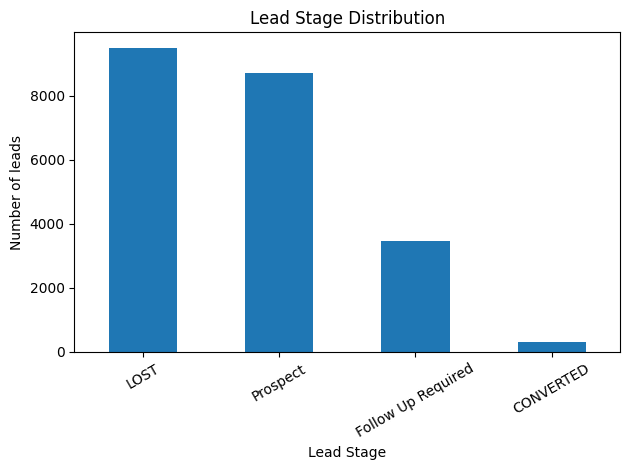

In [ ]:
data['lead_stage'].value_counts().plot(kind='bar')
plt.title("Lead Stage Distribution")
plt.xlabel("Lead Stage")
plt.ylabel("Number of leads")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
source_covertion = (
    data.groupby('source_type')['target'].agg(['count', 'sum', 'mean'])
)
source_covertion.columns = [
    'Total_leads', 'coversion Leads', 'Convertion_rate'
]
source_covertion['Convertion_rate'] *= 100
print(source_covertion.sort_values('Convertion_rate', ascending=False))

                  Total_leads  coversion Leads  Convertion_rate
source_type                                                    
WALK_IN_LEAD               21                1         4.761905
FACEBOOK_ADS             1049               23         2.192564
INSTAGRAM               14051              256         1.821934
MOVE_LEAD                2448               18         0.735294
FILE_UPLOAD              4459               16         0.358825
NEODOVE_DIAL_PAD            1                0         0.000000


In [ ]:
campaign_analysis = (
    data.groupby('campaign_name')['target'].agg(['count', 'sum', 'mean'])
)

campaign_analysis.columns = [
    'Total_leads', 'Coverted_leads', 'Convertion_rate'
]

campaign_analysis['Convertion_rate'] *= 100
display(
    campaign_analysis.sort_values('Total_leads', ascending=False)
)

,Total_leads,Coverted_leads,Convertion_rate
campaign_name,,,
Refurbished Campaign,4105,6,0.146163
Data Analytics Knovista,3561,58,1.628756
BA NEW 18-08-2025,3303,33,0.999092
Python Knovista New,2298,48,2.088773
Digital Marketing Knovista,2012,15,0.745527
Python Knovista,1193,38,3.185247
Business Accounting,830,64,7.710843
Refurbished Campaign-BA,796,8,1.005025
Refurbished Campaign- DM,589,2,0.339559


In [ ]:
feature = [
    'campaign_name',
    'source_type',
    'source_name',
    'assigned_to',
    'month',
    'day_of_week',
    'hour'
]

x = data[feature]
y = data['target']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
x.head()

,campaign_name,source_type,source_name,assigned_to,month,day_of_week,hour
0,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,Anshad,2.0,1.0,22.0
1,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS,Anshad,2.0,1.0,21.0
2,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,Anshad,2.0,1.0,21.0
3,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,Anshad,2.0,1.0,19.0
4,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,Anshad,2.0,1.0,19.0


In [ ]:
cat_col = [
    'campaign_name', 'source_type',
    'source_name', 'assigned_to'
]

num_col = [
    'month',
    'day_of_week',
    'hour'
]

In [ ]:
preprocessor = ColumnTransformer([
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_col),

    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_col)
])

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

for name, algorithm in models.items():

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', algorithm)
    ])

    model.fit(X_train, y_train)
    trained_models[name] = model

    print(name, "trained successfully")

Logistic Regression trained successfully
Random Forest trained successfully


In [ ]:
new_lead = pd.DataFrame([{
    'campaign_name': 'Data Analytics Knovista',
    'source_type': 'INSTAGRAM',
    'source_name': 'INSTAGRAM',
    'assigned_to': 'Anshad',
    'month': 10,
    'day_of_week': 1,
    'hour': 14
}])

model = trained_models['Random Forest']

probability = model.predict_proba(new_lead)[0, 1]

print(f"Conversion probability: {probability:.2%}")

if probability >= 0.5:
    print("Prediction: Likely to convert")
else:
    print("Prediction: Not flagged as likely to convert")

Conversion probability: 34.78%
Prediction: Not flagged as likely to convert
